# A short tour of Reed

Reed is a quiet place to think with code. Prose reads like a page — **bold**, *italic*, `inline code`, [links](https://jupyter.org) — and code sits on the same page, set apart by a faint tint.

- Press **⇧↩** to run a cell and move on
- Press **⌘K** for every command
- Press **esc**, then **H**, to see the whole keyboard on one page
- 中文排版同样舒适：行高、字距与标点都经过调校

> “Simplicity is the ultimate sophistication.”

In [8]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
n = 200

## Data

A small table of random walks. The math behind it: each step is drawn from $\mathcal{N}(0, 1)$, so after $t$ steps

$$
\operatorname{Var}(X_t) = \sum_{i=1}^{t} \sigma^2 = t\,\sigma^2 .
$$

In [9]:
df = pd.DataFrame({
    "t": np.arange(n),
    "walk_a": rng.normal(size=n).cumsum(),
    "walk_b": rng.normal(size=n).cumsum(),
    "group": rng.choice(["alpha", "beta", "gamma"], size=n),
})
df.head(8)

,t,walk_a,walk_b,group
0,0,0.001230,-1.246593,beta
1,1,0.299976,-0.384870,gamma
2,2,0.025838,0.109062,alpha
3,3,-0.864754,0.982681,alpha
4,4,-1.319425,2.861690,beta
5,5,-2.311071,4.346135,gamma
6,6,-2.250928,3.200958,beta
7,7,-0.910712,1.512287,gamma


In [3]:
df.describe().round(3)

,t,walk_a,walk_b
count,200.000,200.000,200.000
mean,99.500,-18.366,-11.036
std,57.879,8.464,4.693
min,0.000,-32.933,-17.530
25%,49.750,-24.638,-14.272
50%,99.500,-16.814,-11.725
75%,149.250,-14.061,-9.317
max,199.000,0.300,4.346


## Plots

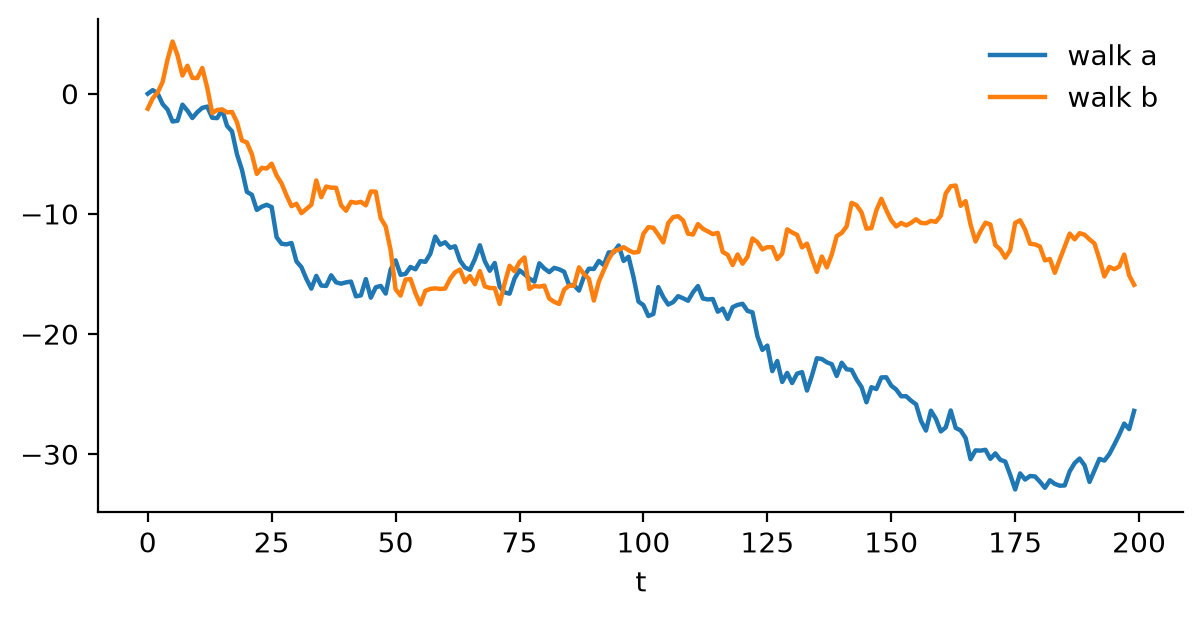

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(df.t, df.walk_a, label="walk a", lw=1.6)
ax.plot(df.t, df.walk_b, label="walk b", lw=1.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_xlabel("t")
plt.show()

## Streams, progress and errors

In [5]:
import time, sys
for i in range(5):
    print(f"step {i}: loss={1/(i+1):.4f}")
    time.sleep(0.15)
print("warning: this goes to stderr", file=sys.stderr)

step 0: loss=1.0000
step 1: loss=0.5000
step 2: loss=0.3333
step 3: loss=0.2500
step 4: loss=0.2000


In [6]:
from tqdm import tqdm
total = 0
for i in tqdm(range(60), desc="crunching"):
    total += i
    time.sleep(0.02)
total

crunching: 100%|██████████| 60/60 [00:01<00:00, 41.80it/s]


1770

In [7]:
def inverse(x):
    return 1 / x

inverse(0)

ZeroDivisionError: division by zero

## Tasks

- [x] Render markdown
- [x] Run code
- [ ] Take over the world